IMPORT LIBRAIRIE

In [22]:
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, accuracy_score


Chargement

In [23]:
test = pd.read_csv("test.csv")
train = pd.read_csv("train.csv")

In [24]:
print(test.columns)

Index(['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


In [25]:
print(test.head())
print(test.info())

   PassengerId  Pclass                                          Name     Sex  \
0          892       3                              Kelly, Mr. James    male   
1          893       3              Wilkes, Mrs. James (Ellen Needs)  female   
2          894       2                     Myles, Mr. Thomas Francis    male   
3          895       3                              Wirz, Mr. Albert    male   
4          896       3  Hirvonen, Mrs. Alexander (Helga E Lindqvist)  female   

    Age  SibSp  Parch   Ticket     Fare Cabin Embarked  
0  34.5      0      0   330911   7.8292   NaN        Q  
1  47.0      1      0   363272   7.0000   NaN        S  
2  62.0      0      0   240276   9.6875   NaN        Q  
3  27.0      0      0   315154   8.6625   NaN        S  
4  22.0      1      1  3101298  12.2875   NaN        S  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       ------------

In [26]:
print(train.head())
print(train.info())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
<c

In [27]:
# 1. Extraire le titre depuis le nom
for df in [train, test]:
    df['Title'] = df['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)


# Regrouper certains titres rares
for df in [train, test]:
    df['Title'] = df['Title'].replace(['Lady', 'Countess', 'Capt', 'Col',
                                       'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')
    df['Title'] = df['Title'].replace('Mlle', 'Miss')
    df['Title'] = df['Title'].replace('Ms', 'Miss')
    df['Title'] = df['Title'].replace('Mme', 'Mrs')

# Encodage du titre
title_encoder = LabelEncoder()
train['Title'] = title_encoder.fit_transform(train['Title'])
test['Title'] = title_encoder.transform(test['Title'])

# 2. Taille de la famille
for df in [train, test]:
    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

# 3. Présence de cabine
for df in [train, test]:
    df['HasCabin'] = df['Cabin'].notnull().astype(int)

# Encodage du sexe
passenger_sex = LabelEncoder()
passenger_sex.fit(train['Sex'])
train['Sex'] = passenger_sex.transform(train['Sex'])

# Même principe pour 'Embarked'
embarked = LabelEncoder()
train['Embarked'] = train['Embarked'].fillna('S')   # ✅ Correction ici
embarked.fit(train['Embarked'])
train['Embarked'] = embarked.transform(train['Embarked'])

# Ensuite seulement : transformer test
test['Sex'] = passenger_sex.transform(test['Sex'])
test['Embarked'] = test['Embarked'].fillna('S')     # ✅ Correction ici
test['Embarked'] = embarked.transform(test['Embarked'])

features = [
    'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
    'Embarked', 'Title', 'FamilySize', 'HasCabin'
]


Accuracy : 0.8268156424581006
              precision    recall  f1-score   support

           0       0.85      0.86      0.85       105
           1       0.79      0.78      0.79        74

    accuracy                           0.83       179
   macro avg       0.82      0.82      0.82       179
weighted avg       0.83      0.83      0.83       179



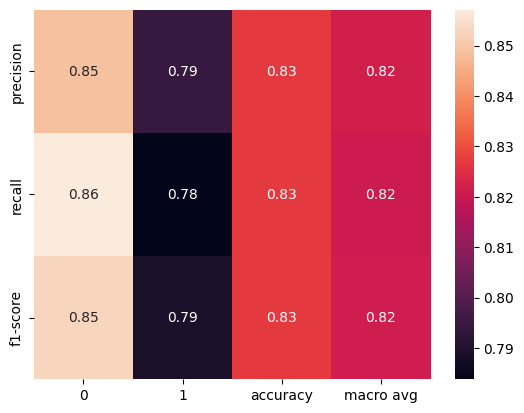

In [28]:


X_train = train[features]
y_train = train['Survived']
X_test = test[features]

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
predictions = model.predict(X_test)


submission = pd.DataFrame({
    'PassengerId': test['PassengerId'],
    'Survived': predictions
})
X_train_split, X_val, y_train_split, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)
model.fit(X_train_split, y_train_split)
y_pred = model.predict(X_val)

print("Accuracy :", accuracy_score(y_val, y_pred))
print(classification_report(y_val, y_pred))

submission.to_csv('titanic_submission.csv', index=False)

#Ajouter une matrice de confusion
matrice = sns.heatmap(pd.DataFrame(classification_report(y_val, y_pred, output_dict=True)).iloc[:-1, :-1], annot=True, fmt='.2f')
